# Pjesa I · 4/4: Transformimi dhe reduktimi i dimensionit

**Qëllimi:** të përgatisim vetitë numerike për metodat që varen nga shkalla dhe shpërndarja e vlerave (korrelacioni, PCA, modelet). Së pari matim sa asimetrike janë kolonat, pastaj i transformojmë (logaritmi, rrënja katrore) dhe i shkallëzojmë (min-max, z-score). Në fund zgjedhim nënbashkësinë e vetive dhe zvogëlojmë dimensionin.

**Hyrja:** `dataset/listings_features.csv`, tabela me vetitë e reja nga notebook-u 03. Ekzekutoni së pari notebook-et 02 dhe 03.

**Dalja:** `dataset/listings_transformed.csv`, e njëjta tabelë me kolonat e transformuara (`_log`, `_sqrt`) dhe të shkallëzuara (`_minmax`, `_z`).

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get("PVDH_PROJECT_ROOT", Path.cwd()))
if not (ROOT / "dataset" / "listings_features.csv").is_file() and (ROOT.parent / "dataset" / "listings_features.csv").is_file():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "dataset" / "listings_features.csv"
assert DATA_PATH.is_file(), f"Mungon {DATA_PATH.name}: ekzekutoni notebook-un 03."
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Hyrja: {DATA_PATH.name} | Rreshta: {len(df):,} | Kolona: {df.shape[1]}")

Hyrja: listings_features.csv | Rreshta: 59,846 | Kolona: 117


## 1. Asimetria para transformimit

**Asimetria** (*skewness*) tregon sa e zhvendosur është shpërndarja. Vlera pozitive do të thotë një "bisht" i gjatë djathtas: shumica e listimeve kanë vlera të vogla dhe pak listime kanë vlera shumë të mëdha (p.sh. pak host-e me qindra listime). Kjo ka rëndësi sepse:

- mesatarja dhe devijimi standard tërhiqen nga vlerat e mëdha;
- korrelacioni dhe PCA i japin peshë të tepërt atyre pak vlerave;
- standardizimi (z-score) nuk e ndreq asimetrinë, vetëm e zhvendos dhe e shkallëzon.

Rregulli i zakonshëm: |asimetria| < 0.5 është afërsisht simetrike, 0.5–1 mesatarisht asimetrike dhe > 1 shumë asimetrike.

Shqyrtojmë vetitë numerike me kuptim për analizën e çmimit. Nuk përfshijmë ID-të, koordinatat, kolonat 0/1 (binare dhe one-hot) dhe kolonat `price_quote_*`, që janë kopje të çmimit.

,asimetria,kategoria,min,mediana,mesatarja,max,bosh
price_per_person,17.93,shumë asimetrike,1.50,55.50,70.99,5000.00,0
minimum_nights,16.47,shumë asimetrike,1.00,2.00,3.73,365.00,298
host_listings_count,10.61,shumë asimetrike,0.00,4.00,68.08,5777.00,0
price,8.31,shumë asimetrike,10.00,175.00,237.16,6798.40,0
calculated_host_listings_count,7.05,shumë asimetrike,1.00,3.00,18.47,501.00,0
number_of_reviews_ltm,6.38,shumë asimetrike,0.00,3.00,8.87,789.00,0
number_of_reviews,5.49,shumë asimetrike,0.00,8.00,31.22,1705.00,0
reviews_per_month,4.69,shumë asimetrike,0.00,0.54,1.09,55.84,0
bathrooms,4.48,shumë asimetrike,0.00,1.00,1.35,30.00,0
days_since_last_review,4.04,shumë asimetrike,0.00,39.00,206.20,5289.00,12226


kategoria
shumë asimetrike          15
simetrike                  3
mesatarisht asimetrike     2


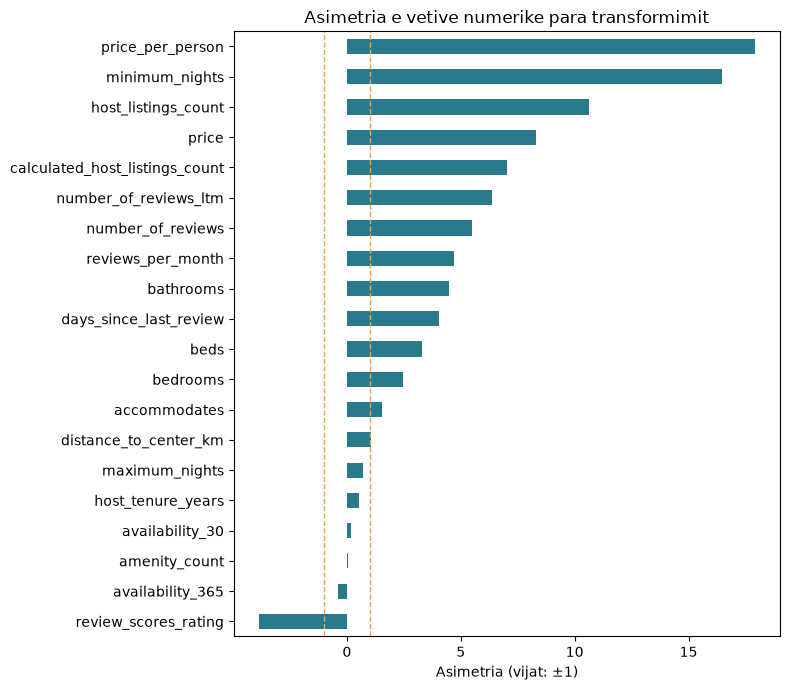

In [2]:
NUMERIC_FEATURES = [
    "price", "price_per_person", "accommodates", "bathrooms", "bedrooms", "beds", "minimum_nights", "maximum_nights",
    "availability_30", "availability_365", "number_of_reviews", "number_of_reviews_ltm", "reviews_per_month",
    "review_scores_rating", "host_listings_count", "calculated_host_listings_count", "host_tenure_years",
    "distance_to_center_km", "amenity_count", "days_since_last_review",
]
missing_columns = [col for col in NUMERIC_FEATURES if col not in df]
assert not missing_columns, f"Mungojnë kolonat: {missing_columns}"

def skew_label(value):
    if abs(value) < 0.5:
        return "simetrike"
    return "mesatarisht asimetrike" if abs(value) <= 1 else "shumë asimetrike"

skew_before = df[NUMERIC_FEATURES].skew()
skew_table = pd.DataFrame({
    "asimetria": skew_before.round(2),
    "kategoria": skew_before.map(skew_label),
    "min": df[NUMERIC_FEATURES].min(),
    "mediana": df[NUMERIC_FEATURES].median(),
    "mesatarja": df[NUMERIC_FEATURES].mean().round(2),
    "max": df[NUMERIC_FEATURES].max(),
    "bosh": df[NUMERIC_FEATURES].isna().sum(),
}).round(2).sort_values("asimetria", ascending=False)
display(skew_table)
print(skew_table["kategoria"].value_counts().to_string())

ax = skew_before.sort_values().plot.barh(figsize=(8, 7), color="#287a8c")
for limit in (-1, 1):
    ax.axvline(limit, color="#e4a64c", linestyle="--", linewidth=1)
ax.set(xlabel="Asimetria (vijat: ±1)", ylabel="", title="Asimetria e vetive numerike para transformimit")
plt.tight_layout()
plt.show()

**Përfundim.** Kolonat me asimetri pozitive mbi 1 janë kandidate për transformim në seksionin 2. Te shumica e tyre mesatarja është shumë më e madhe se mediana, shenjë e bishtit të gjatë djathtas. `review_scores_rating` ka asimetri **negative**: shumica e notave janë afër maksimumit 5. Logaritmi nuk e ndihmon këtë rast, sepse ngjesh vlerat e mëdha, ndërsa këtu bishti është majtas; prandaj kjo kolonë nuk transformohet.

## 2. Transformimi me logaritëm dhe rrënjë katrore

Për kolonat me asimetri pozitive mbi 1 provojmë dy transformime që ngjeshin vlerat e mëdha:

- **logaritmi** `log1p(x) = log(1 + x)`: ngjeshje e fortë. Përdorim `log1p` dhe jo `log`, sepse shumë kolona kanë vlerën 0 (p.sh. listime pa komente) dhe `log(0)` nuk është i përcaktuar;
- **rrënja katrore** `sqrt(x)`: ngjeshje më e butë, e mjaftueshme për kolonat pak asimetrike.

Për secilën kolonë zgjedhim transformimin që e afron asimetrinë më shumë me 0. Kolona origjinale mbetet; versioni i transformuar ruhet si kolonë e re me prapashtesën `_log` ose `_sqrt`. Vlerat që mungojnë mbeten bosh.

Për `price`, nëse më vonë një model parashikon `price_log`, rezultati kthehet në çmim me `expm1`, funksionin e anasjelltë të `log1p`.

In [3]:
TRANSFORMS = {"log": np.log1p, "sqrt": np.sqrt}
skewed = skew_before[skew_before.gt(1)].sort_values(ascending=False).index.tolist()

rows = []
for col in skewed:
    skew_after = {name: transform(df[col]).skew() for name, transform in TRANSFORMS.items()}
    best = min(skew_after, key=lambda name: abs(skew_after[name]))
    new_col = f"{col}_{best}"
    df[new_col] = TRANSFORMS[best](df[col])
    rows.append({"kolona": col, "para": skew_before[col], "pas log1p": skew_after["log"], "pas sqrt": skew_after["sqrt"],
                 "zgjedhja": best, "kolona e re": new_col})
transform_table = pd.DataFrame(rows).set_index("kolona").round(2)
display(transform_table)

TRANSFORMED = transform_table["kolona e re"].tolist()
still_skewed = df[TRANSFORMED].skew().loc[lambda s: s.abs() > 1]
print(f"Kolona shumë asimetrike: {len(skewed)} para transformimit → {len(still_skewed)} pas tij")
print("Ende mbi 1:", ", ".join(f"{col} ({value:.2f})" for col, value in still_skewed.items()) or "asnjë")
assert df[TRANSFORMED].isna().sum().equals(df[skewed].isna().sum().set_axis(TRANSFORMED)), "Transformimi nuk duhet të krijojë mungesa të reja"


,para,pas log1p,pas sqrt,zgjedhja,kolona e re
kolona,,,,,
price_per_person,17.93,0.69,3.90,log,price_per_person_log
minimum_nights,16.47,2.36,5.49,log,minimum_nights_log
host_listings_count,10.61,1.43,8.14,log,host_listings_count_log
price,8.31,0.31,2.37,log,price_log
calculated_host_listings_count,7.05,1.04,2.99,log,calculated_host_listings_count_log
number_of_reviews_ltm,6.38,0.41,1.12,log,number_of_reviews_ltm_log
number_of_reviews,5.49,0.20,1.69,log,number_of_reviews_log
reviews_per_month,4.69,0.93,0.81,sqrt,reviews_per_month_sqrt
bathrooms,4.48,1.15,0.99,sqrt,bathrooms_sqrt


Kolona shumë asimetrike: 14 para transformimit → 3 pas tij
Ende mbi 1: minimum_nights_log (2.36), host_listings_count_log (1.43), calculated_host_listings_count_log (1.04)


### Para dhe pas: histogramet

Tri shembuj: çmimi, numri i komenteve dhe numri i listimeve të host-it. Para transformimit, pothuajse të gjitha listimet janë të ngjeshura në shiritin e parë; pas tij shpërndarja shtrihet dhe bëhet afërsisht simetrike.

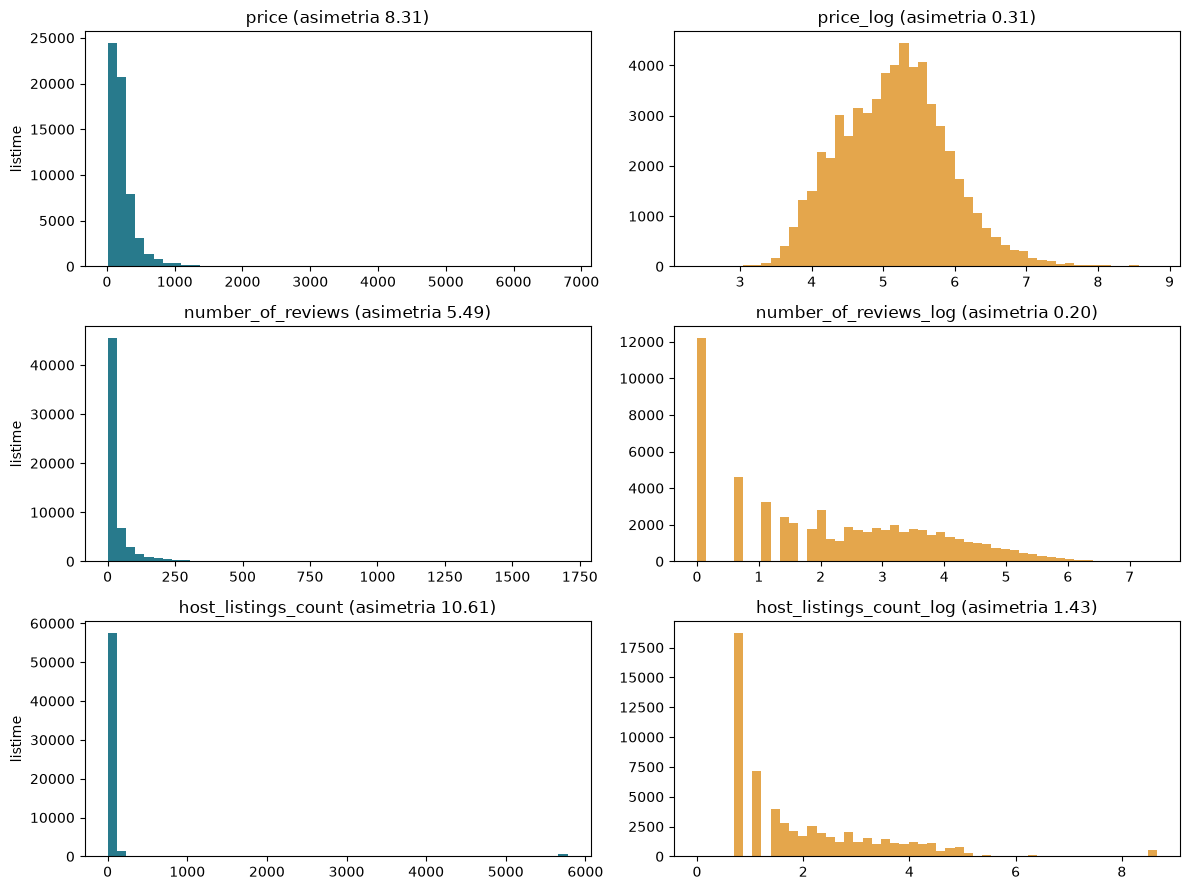

In [4]:
examples = ["price", "number_of_reviews", "host_listings_count"]
fig, axes = plt.subplots(len(examples), 2, figsize=(12, 9))
for (ax_before, ax_after), col in zip(axes, examples):
    new_col = transform_table.loc[col, "kolona e re"]
    df[col].plot.hist(bins=50, ax=ax_before, color="#287a8c")
    ax_before.set(title=f"{col} (asimetria {df[col].skew():.2f})", ylabel="listime")
    df[new_col].plot.hist(bins=50, ax=ax_after, color="#e4a64c")
    ax_after.set(title=f"{new_col} (asimetria {df[new_col].skew():.2f})", ylabel="")
plt.tight_layout()
plt.show()

**Përfundim.** Transformimi e ul fort asimetrinë te shumica e kolonave; `price_log` bëhet afërsisht simetrik. Tri kolona mbeten mbi 1. Te `minimum_nights`, shumica e listimeve kanë saktësisht 1 ose 2 netë, dhe asnjë transformim nuk i ndan vlerat e njëjta; grupet sipas domenit (`minimum_nights_cat`) dhe `is_long_stay` nga notebook-u 03 e përfaqësojnë më mirë. Te dy numrat e listimeve të host-it, pak menaxherë profesionalë kanë qindra listime; `is_multi_listing_host` nga notebook-u 03 e kap këtë dallim në mënyrë më të thjeshtë.

## 3. Shkallëzimi: min-max dhe z-score

Vetitë kanë njësi dhe intervale shumë të ndryshme: `accommodates` shkon nga 1 deri në 16, `availability_365` nga 0 deri në 365. Metodat që llogarisin distanca ose varianca (PCA, k-means, k-NN) do t'u jepnin peshë më të madhe kolonave me numra më të mëdhenj, vetëm për shkak të njësisë. Shkallëzimi i sjell në të njëjtën shkallë.

- **Min-max** `(x − min) / (max − min)`: çdo vlerë bie në intervalin [0, 1]. Është i ndjeshëm ndaj vlerave ekstreme: një vlerë shumë e madhe i ngjesh të gjitha të tjerat afër 0.
- **Z-score** `(x − mesatarja) / devijimi standard`: mesatarja bëhet 0 dhe devijimi standard 1. Vlerat tregojnë sa devijime standarde larg mesatares është listimi. Ky përdoret për PCA.

Shkallëzojmë 20 vetitë numerike të seksionit 1, duke përdorur versionin `_log`/`_sqrt` aty ku kolona u transformua. Shkallëzimi ndryshon vetëm njësinë, jo formën e shpërndarjes; prandaj asimetria mbetet e njëjtë dhe transformimi i seksionit 2 bëhet para tij.

**Kujdes për modelet:** këtu min, max, mesatarja dhe devijimi standard llogariten mbi të gjitha listimet, sepse qëllimi është përshkrues. Për një model parashikues, ato llogariten **vetëm në setin e trajnimit** dhe pastaj zbatohen në setin e testimit. Përndryshe informacioni nga testi rrjedh te trajnimi (*data leakage*).

In [5]:
transformed_name = transform_table["kolona e re"].to_dict()
SCALE_FEATURES = [transformed_name.get(col, col) for col in NUMERIC_FEATURES]
values = df[SCALE_FEATURES].astype(float)

minmax = (values - values.min()) / (values.max() - values.min())
zscore = (values - values.mean()) / values.std(ddof=0)
df[[f"{col}_minmax" for col in SCALE_FEATURES]] = minmax.to_numpy()
df[[f"{col}_z" for col in SCALE_FEATURES]] = zscore.to_numpy()

scaling_check = pd.DataFrame({
    "min para": values.min(), "max para": values.max(),
    "min-max: min": minmax.min(), "min-max: max": minmax.max(),
    "z: mesatarja": zscore.mean(), "z: dev. std.": zscore.std(ddof=0),
    "asimetria para": values.skew(), "asimetria pas z": zscore.skew(),
}).round(2) + 0.0  # + 0.0 shfaq -0.0 si 0.0
display(scaling_check)
assert np.allclose(scaling_check[["min-max: min", "z: mesatarja"]], 0) and np.allclose(scaling_check[["min-max: max", "z: dev. std."]], 1)
assert minmax.isna().sum().equals(values.isna().sum()) and zscore.isna().sum().equals(values.isna().sum()), "Shkallëzimi nuk duhet të krijojë mungesa"
print(f"Kolona të shkallëzuara: {len(SCALE_FEATURES)} × 2 metoda = {2 * len(SCALE_FEATURES)} kolona të reja (_minmax dhe _z)")

,min para,max para,min-max: min,min-max: max,z: mesatarja,z: dev. std.,asimetria para,asimetria pas z
price_log,2.40,8.82,0.0,1.0,0.0,1.0,0.31,0.31
price_per_person_log,0.92,8.52,0.0,1.0,0.0,1.0,0.69,0.69
accommodates_log,0.69,2.83,0.0,1.0,0.0,1.0,0.34,0.34
bathrooms_sqrt,0.00,5.48,0.0,1.0,0.0,1.0,0.99,0.99
bedrooms_sqrt,0.00,5.48,0.0,1.0,0.0,1.0,0.11,0.11
beds_log,0.00,3.93,0.0,1.0,0.0,1.0,0.96,0.96
minimum_nights_log,0.69,5.90,0.0,1.0,0.0,1.0,2.36,2.36
maximum_nights,1.00,1125.00,0.0,1.0,0.0,1.0,0.70,0.70
availability_30,0.00,30.00,0.0,1.0,0.0,1.0,0.20,0.20
availability_365,0.00,365.00,0.0,1.0,0.0,1.0,-0.38,-0.38


Kolona të shkallëzuara: 20 × 2 metoda = 40 kolona të reja (_minmax dhe _z)


### Para dhe pas shkallëzimit

Majtas: vlerat origjinale në shkallë logaritmike, sepse intervalet ndryshojnë shumë. Djathtas: të njëjtat veti pas z-score, tani të krahasueshme në një bosht të përbashkët (pa vlerat ekstreme në grafik).

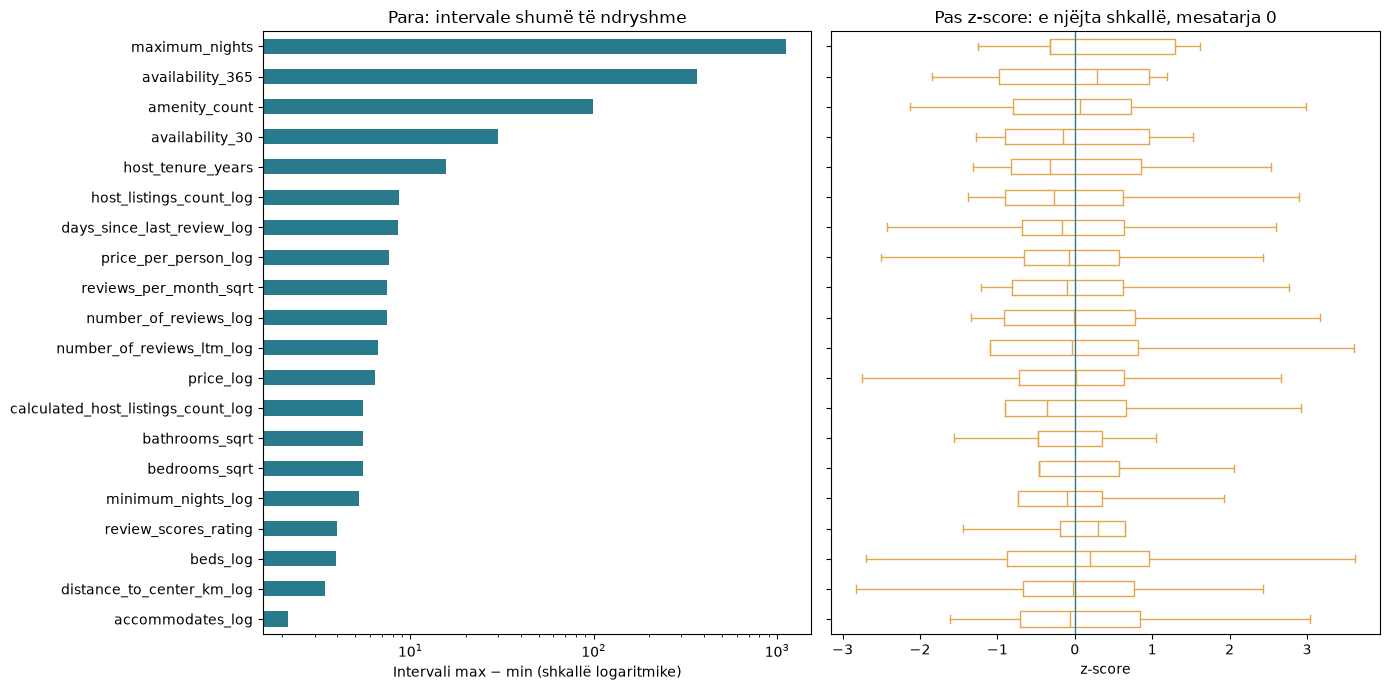

In [6]:
fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(14, 7))
ranges = (values.max() - values.min()).sort_values()
ranges.plot.barh(ax=ax_before, color="#287a8c", logx=True)
ax_before.set(xlabel="Intervali max − min (shkallë logaritmike)", ylabel="", title="Para: intervale shumë të ndryshme")
zscore[ranges.index].plot.box(ax=ax_after, vert=False, showfliers=False, color="#e4a64c")
ax_after.axvline(0, color="#287a8c", linewidth=1)
ax_after.set(xlabel="z-score", title="Pas z-score: e njëjta shkallë, mesatarja 0")
ax_after.set_yticklabels([])
plt.tight_layout()
plt.show()

## 4. Ruajtja

Ruajmë tabelën e plotë me kolonat e reja. Kolonat origjinale mbeten, që çdo transformim të mund të krahasohet me vlerat fillestare. Hapi tjetër, zgjedhja e vetive dhe PCA, përdor kolonat `_z`.

In [7]:
new_columns = df.columns.difference(pd.read_csv(DATA_PATH, nrows=0).columns)
summary = pd.Series({
    "të transformuara (_log, _sqrt)": len(TRANSFORMED),
    "min-max (_minmax)": int(new_columns.str.endswith("_minmax").sum()),
    "z-score (_z)": int(new_columns.str.endswith("_z").sum()),
})
assert summary.sum() == len(new_columns)
display(summary.to_frame("kolona të reja"))

output = ROOT / "dataset" / "listings_transformed.csv"
df.to_csv(output, index=False)
print(f"U ruajt: {output.relative_to(ROOT)} ({len(df):,} rreshta × {df.shape[1]} kolona, nga të cilat {len(new_columns)} të reja)")

,kolona të reja
"të transformuara (_log, _sqrt)",14
min-max (_minmax),20
z-score (_z),20


U ruajt: dataset/listings_transformed.csv (59,846 rreshta × 171 kolona, nga të cilat 54 të reja)


## 5. Zgjedhja e vetive: korrelacioni

Shumë kolona të dataset-it mbajnë pothuajse të njëjtin informacion, p.sh. disponueshmëria për 30, 60, 90 dhe 365 ditë. Kolonat e tepërta nuk shtojnë informacion, por e rëndojnë analizën dhe i japin peshë të dyfishtë të njëjtit faktor në PCA dhe në modele.

**Kolonat e nxjerra nga çmimi** përjashtohen që në fillim, sepse çmimi është variabla që analizojmë: `price` dhe versionet e tij, `price_per_person`, `price_band`, `price_above_p99`, `price_quote_*` dhe `estimated_revenue_l365d` (= çmimi × netët e zëna). Si hyrje modeli do ta zbulonin vetë përgjigjen (*target leakage*).

Për kolonat e tjera përdorim **korrelacionin e Spearman-it** (ρ). Ai krahason renditjen e vlerave, jo vetë vlerat, ndaj nuk ndikohet nga asimetria dhe vlerat ekstreme. Rezultati është i njëjtë për kolonën origjinale dhe për versionin e saj `_log`/`_sqrt`.

**Rregulli:** brenda çdo grupi kolonash të ngjashme, kolonat renditen sipas kuptimit (e para është ajo që e kupton më lehtë një lexues ose mysafir). Shkojmë me radhë: një kolonë mbahet vetëm nëse |ρ| me çdo kolonë të mbajtur më parë është nën **0.8**, kufiri i zakonshëm për korrelacion shumë të fortë.

In [8]:
target_derived = [col for col in df.columns if col.startswith(("price", "estimated_revenue"))]
print(f"Kolona të nxjerra nga çmimi, të përjashtuara: {len(target_derived)}")
print(", ".join(col for col in target_derived if not col.endswith(("_minmax", "_z"))))

REDUNDANCY_THRESHOLD = 0.8
REDUNDANCY_GROUPS = {
    "kapaciteti": ["accommodates", "bedrooms", "bathrooms", "beds"],
    "disponueshmëria": ["availability_365", "availability_30", "availability_90", "availability_60", "availability_eoy",
                        "calendar_available_days", "calendar_weekend_availability"],
    "netët minimale": ["minimum_nights", "minimum_nights_avg_ntm", "maximum_minimum_nights", "minimum_minimum_nights"],
    "netët maksimale": ["maximum_nights", "maximum_nights_avg_ntm", "minimum_maximum_nights", "maximum_maximum_nights"],
    "listimet e host-it": ["calculated_host_listings_count", "calculated_host_listings_count_entire_homes",
                           "calculated_host_listings_count_private_rooms", "calculated_host_listings_count_shared_rooms",
                           "host_listings_count"],
    "notat e komenteve": ["review_scores_rating", "review_scores_location", "review_scores_cleanliness", "review_scores_checkin",
                          "review_scores_communication", "review_scores_value", "review_scores_accuracy"],
    "numri i komenteve": ["number_of_reviews", "reviews_per_month", "number_of_reviews_ltm", "number_of_reviews_l30d",
                          "number_of_reviews_ly", "reviews_in_file", "estimated_occupancy_l365d"],
}
missing_columns = [col for cols in REDUNDANCY_GROUPS.values() for col in cols if col not in df]
assert not missing_columns, f"Mungojnë kolonat: {missing_columns}"

group_corr = {}
decisions = []
for group, cols in REDUNDANCY_GROUPS.items():
    rho = df[cols].corr(method="spearman")
    group_corr[group] = rho
    kept = []
    for col in cols:
        partner = rho.loc[col, kept].abs().idxmax() if kept else None
        value = rho.loc[col, partner] if partner else np.nan
        keep = partner is None or abs(value) < REDUNDANCY_THRESHOLD
        if keep:
            kept.append(col)
        decisions.append({"grupi": group, "kolona": col, "vendimi": "mbahet" if keep else "hiqet",
                          "më e lidhura e mbajtur": partner or "—", "ρ": value})
redundancy = pd.DataFrame(decisions).set_index(["grupi", "kolona"]).round(2)
with pd.option_context("display.max_rows", None):
    display(redundancy)
print(redundancy["vendimi"].value_counts().to_string())

print(f"is_superhost është kopje e host_is_superhost: {df['is_superhost'].astype(bool).equals(df['host_is_superhost'].astype(bool))}; mbahet is_superhost (0/1).")

Kolona të nxjerra nga çmimi, të përjashtuara: 16
price, price_quote_checkin_date, price_quote_checkout_date, price_quote_total_price, price_quote_price_per_night, price_quote_raw, estimated_revenue_l365d, price_above_p99, price_band, price_per_person, price_per_person_log, price_log


vendimi  \
grupi              kolona                                                 
kapaciteti         accommodates                                  mbahet   
                   bedrooms                                      mbahet   
                   bathrooms                                     mbahet   
                   beds                                           hiqet   
disponueshmëria    availability_365                              mbahet   
                   availability_30                               mbahet   
                   availability_90                                hiqet   
                   availability_60                                hiqet   
                   availability_eoy                               hiqet   
                   calendar_available_days                        hiqet   
                   calendar_weekend_availability                  hiqet   
netët minimale     minimum_nights                                mbahet   
                   minimum_nights_avg_ntm                        mbahet   
                   maximum_minimum_nights                         hiqet   
                   minimum_minimum_nights                         hiqet   
netët maksimale    maximum_nights                                mbahet   
                   maximum_nights_avg_ntm                         hiqet   
                   minimum_maximum_nights                         hiqet   
                   maximum_maximum_nights                         hiqet   
listimet e host-it calculated_host_listings_count                mbahet   
                   calculated_host_listings_count_entire_homes   mbahet   
                   calculated_host_listings_count_private_rooms  mbahet   
                   calculated_host_listings_count_shared_rooms   mbahet   
                   host_listings_count                            hiqet   
notat e komenteve  review_scores_rating                          mbahet   
                   review_scores_location                        mbahet   
                   review_scores_cleanliness                     mbahet   
                   review_scores_checkin                         mbahet   
                   review_scores_communication                   mbahet   
                   review_scores_value                           mbahet   
                   review_scores_accuracy                         hiqet   
numri i komenteve  number_of_reviews                             mbahet   
                   reviews_per_month                             mbahet   
                   number_of_reviews_ltm                          hiqet   
                   number_of_reviews_l30d                        mbahet   
                   number_of_reviews_ly                          mbahet   
                   reviews_in_file                                hiqet   
                   estimated_occupancy_l365d                      hiqet   

                                                                                       më e lidhura e mbajtur  \
grupi              kolona                                                                                       
kapaciteti         accommodates                                                                             —   
                   bedrooms                                                                      accommodates   
                   bathrooms                                                                         bedrooms   
                   beds                                                                          accommodates   
disponueshmëria    availability_365                                                                         —   
                   availability_30                                                           availability_365   
                   availability_90                                                            availability_30   
                   availability_60            

vendimi
mbahet    22
hiqet     16
is_superhost është kopje e host_is_superhost: True; mbahet is_superhost (0/1).


### Matricat e korrelacionit sipas grupit

Ngjyra e errët do të thotë korrelacion i fortë. Katrorët me vlerë afër 1 jashtë diagonales tregojnë kolona që mbajnë të njëjtin informacion.

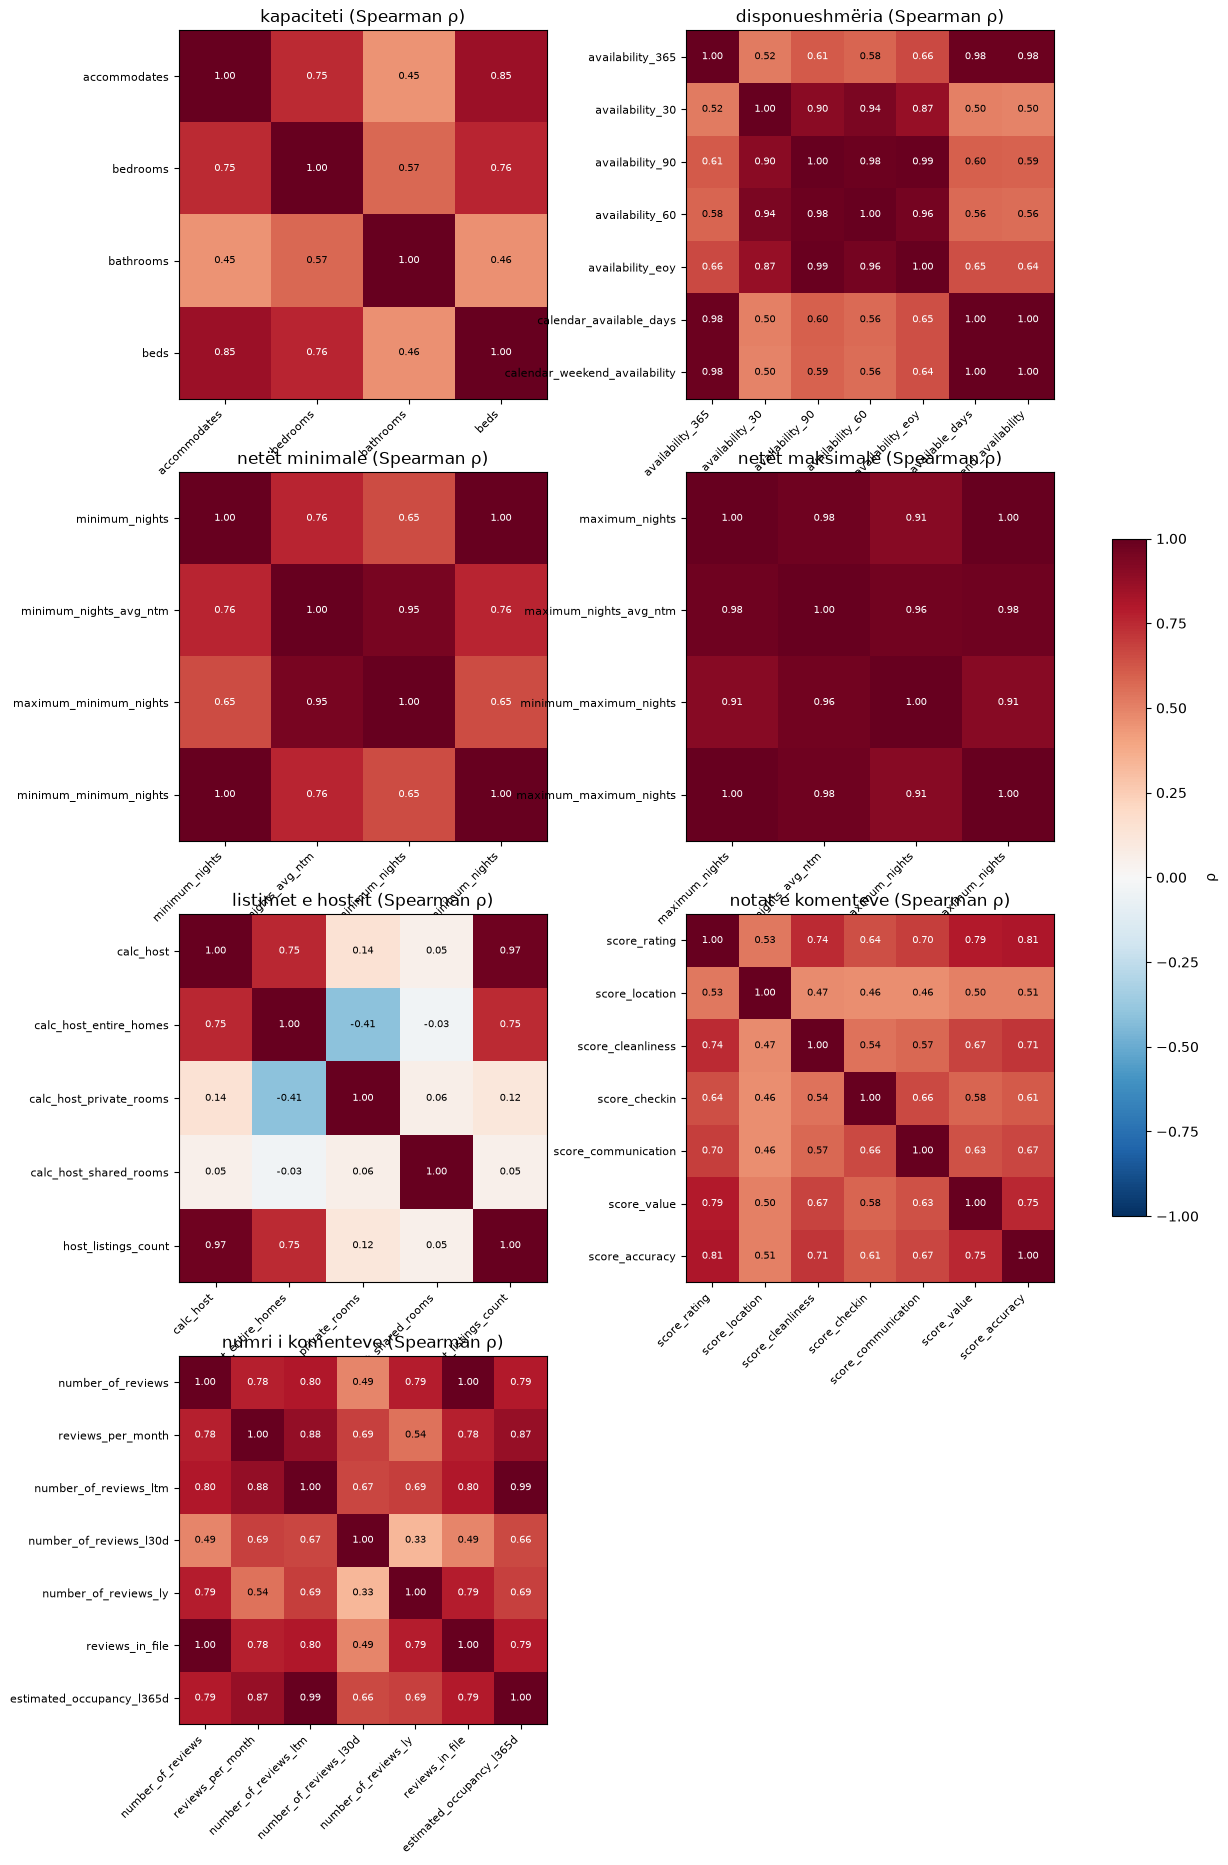

In [9]:
fig, axes = plt.subplots(4, 2, figsize=(15, 22))
for ax, (group, rho) in zip(axes.flat, group_corr.items()):
    image = ax.imshow(rho, vmin=-1, vmax=1, cmap="RdBu_r")
    labels = [col.replace("calculated_host_listings_count", "calc_host").replace("review_scores_", "score_") for col in rho.columns]
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(labels)), labels, fontsize=8)
    for i in range(len(rho)):
        for j in range(len(rho)):
            ax.text(j, i, f"{rho.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(rho.iat[i, j]) > 0.6 else "black")
    ax.set_title(f"{group} (Spearman ρ)")
axes.flat[-1].axis("off")
fig.colorbar(image, ax=axes, shrink=0.4, label="ρ")
plt.show()

**Përfundim.** Shumica e kolonave të hequra janë variante të së njëjtës matje: `minimum_minimum_nights` dhe `minimum_nights` kanë ρ = 1.00, `reviews_in_file` (nga integrimi) është kopje e `number_of_reviews`, dhe kolonat e kalendarit (`calendar_*`) përputhen me `availability_365`. Te kapaciteti, `beds` hiqet sepse e ndjek nga afër `accommodates`; `bedrooms` dhe `bathrooms` mbeten sepse sjellin informacion shtesë. Notat e komenteve janë të lidhura (0.46–0.81), por vetëm `review_scores_accuracy` e kalon kufirin: notat e tjera matin aspekte të ndryshme (vendndodhja, pastërtia, komunikimi).

## 6. Zgjedhja e vetive: varianca

Një kolonë që ka pothuajse gjithmonë të njëjtën vlerë nuk ndihmon të dallohen listimet: p.sh. nëse 99% e listimeve kanë disponueshmëri, kolona `has_availability` nuk tregon pothuajse asgjë për ndryshimet e çmimit. Kolona të tilla kanë variancë afër 0.

Pas z-score, varianca e çdo kolone është 1, ndaj nuk mund të krahasohet më. Prandaj matim **pjesën e vlerës më të shpeshtë** në vlerat origjinale. **Rregulli:** një kolonë hiqet si *pothuajse konstante* kur një vlerë e vetme mbulon mbi **98%** të listimeve.

Kandidatët janë kolonat e mbajtura nga korrelacioni (seksioni 5), vetitë e tjera numerike, flamujt binarë dhe kolonat one-hot.

**Kolonat one-hot trajtohen ndryshe.** Kategoritë e rralla (p.sh. `room_hotel_room`, 0.2% e listimeve) kanë pothuajse gjithmonë 0, por heqja e tyre do t'i fuste ato listime pa dallim te kategoritë e tjera. Ato mbahen. Në vend të kësaj, nga çdo grup one-hot hiqet **një kolonë referencë**, kategoria më e shpeshtë. Kolonat e një grupi mblidhen gjithmonë në 1, ndaj njëra prej tyre është e tepërt (*dummy trap*): vlera e saj del nga të tjerat.

In [10]:
NEAR_CONSTANT_SHARE = 0.98
kept_after_corr = redundancy.index[redundancy["vendimi"].eq("mbahet")].get_level_values("kolona").tolist()
OTHER_NUMERIC = ["host_tenure_years", "distance_to_center_km", "amenity_count", "days_since_last_review", "borough_frequency"]
BINARY_FEATURES = ["has_reviews", "is_superhost", "has_availability", "host_identity_verified", "host_has_profile_pic",
                   "is_multi_listing_host", "is_long_stay", "is_inner_london", "is_previous_scrape", "bedrooms_above_accommodates",
                   "has_wifi", "has_kitchen", "has_ac", "has_heating", "has_washer", "has_parking", "has_tv", "has_workspace"]
ONE_HOT_GROUPS = {"room_type": [col for col in df.columns if col.startswith("room_") and col != "room_type"],
                  "property_group": [col for col in df.columns if col.startswith("property_") and col not in ("property_type", "property_group")]}
candidates = kept_after_corr + OTHER_NUMERIC + BINARY_FEATURES
missing_columns = [col for col in candidates + sum(ONE_HOT_GROUPS.values(), []) if col not in df]
assert not missing_columns, f"Mungojnë kolonat: {missing_columns}"

rows = []
for col in candidates:
    counts = df[col].value_counts(normalize=True)
    near_constant = counts.iloc[0] > NEAR_CONSTANT_SHARE
    rows.append({"kolona": col, "lloji": "binare" if col in BINARY_FEATURES else "numerike", "vlera më e shpeshtë": counts.index[0],
                 "pjesa e saj (%)": counts.iloc[0] * 100, "vlera të ndryshme": df[col].nunique(),
                 "vendimi": "hiqet: pothuajse konstante" if near_constant else "mbahet"})
for group, cols in ONE_HOT_GROUPS.items():
    reference = df[cols].sum().idxmax()
    for col in cols:
        share_of_ones = df[col].mean()
        rows.append({"kolona": col, "lloji": f"one-hot ({group})", "vlera më e shpeshtë": int(share_of_ones > 0.5),
                     "pjesa e saj (%)": max(share_of_ones, 1 - share_of_ones) * 100, "vlera të ndryshme": 2,
                     "vendimi": "hiqet: referenca e grupit" if col == reference else "mbahet"})
variance = pd.DataFrame(rows).set_index("kolona").sort_values("pjesa e saj (%)", ascending=False).round(2)
with pd.option_context("display.max_rows", None):
    display(variance)
print(variance["vendimi"].value_counts().to_string())
selected_after_variance = variance.index[variance["vendimi"].eq("mbahet")].tolist()
print(f"Kandidatë: {len(variance)} → të mbajtur pas kontrollit të variancës: {len(selected_after_variance)}")

,lloji,vlera më e shpeshtë,pjesa e saj (%),vlera të ndryshme,vendimi
kolona,,,,,
property_other,one-hot (property_group),0,99.83,2,mbahet
room_hotel_room,one-hot (room_type),0,99.78,2,mbahet
room_shared_room,one-hot (room_type),0,99.73,2,mbahet
property_unique,one-hot (property_group),0,99.61,2,mbahet
has_availability,binare,1,99.43,2,hiqet: pothuajse konstante
calculated_host_listings_count_shared_rooms,numerike,0,99.43,13,hiqet: pothuajse konstante
bedrooms_above_accommodates,binare,False,99.37,2,hiqet: pothuajse konstante
property_guest_suite,one-hot (property_group),0,98.73,2,mbahet
host_identity_verified,binare,1,98.45,2,hiqet: pothuajse konstante


vendimi
mbahet                        48
hiqet: pothuajse konstante     5
hiqet: referenca e grupit      2
Kandidatë: 55 → të mbajtur pas kontrollit të variancës: 48


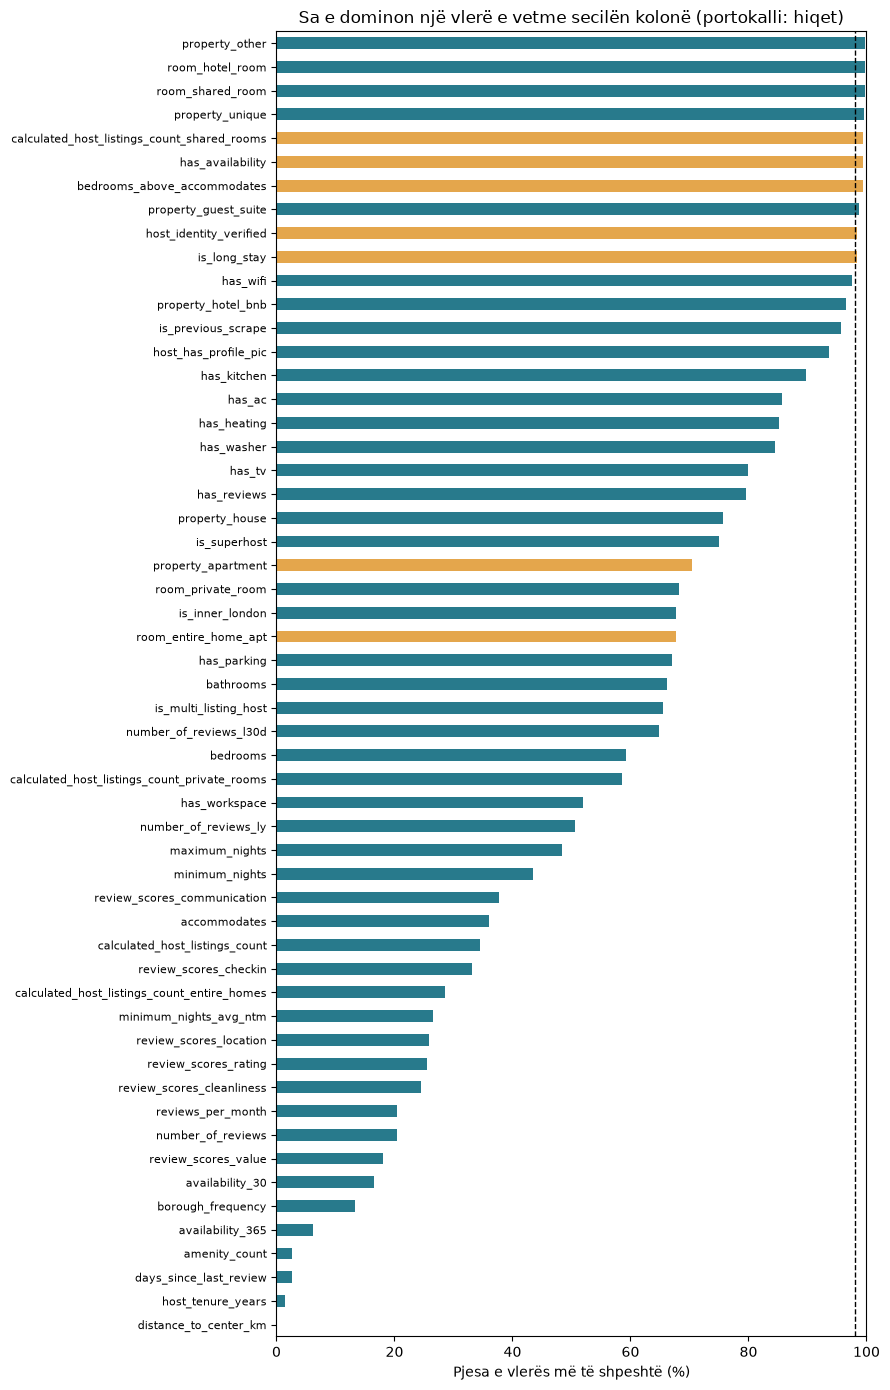

In [11]:
shares = variance["pjesa e saj (%)"].sort_values()
colors = ["#e4a64c" if decision.startswith("hiqet") else "#287a8c" for decision in variance.loc[shares.index, "vendimi"]]
ax = shares.plot.barh(figsize=(9, 14), color=colors)
ax.axvline(NEAR_CONSTANT_SHARE * 100, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="Pjesa e vlerës më të shpeshtë (%)", ylabel="", xlim=(0, 100),
       title="Sa e dominon një vlerë e vetme secilën kolonë (portokalli: hiqet)")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

**Përfundim.** Kolonat pothuajse konstante janë flamuj ku pothuajse të gjitha listimet kanë të njëjtën përgjigje: `has_availability`, `host_identity_verified`, `bedrooms_above_accommodates` (anomali e rrallë, e shënuar në notebook-un 02), `is_long_stay` dhe numri i dhomave të përbashkëta të host-it. Informacioni i `is_long_stay` mbetet te `minimum_nights`. `has_wifi` është afër kufirit (rreth 97.5%) dhe mbahet sipas rregullit, por kontribuon pak. Nga grupet one-hot hiqen kategoritë referencë `room_entire_home_apt` dhe `property_apartment`.

**Vazhdon:** zgjedhja e nënbashkësisë së vetive (matrica e korrelacionit, varianca) dhe reduktimi i dimensionit me PCA.